# Using Clustering Techniques to Group Exoplanets by Radius and Discovery Year
Adam Noonan | C00299231

## Introduction

In my exploration of exoplanets using linear regression techniques, I noted that the graph of exoplanet radius over discovery year could not be neatly described by a linear function, rather the data seemed to dip arbitrarily around a certain year. For this reason I thought a clustering algorithm could be more effective at describing the data. blah blah

## Data
The selected dataset is the same as the dataset used in my linear regression exploration. It's a cut-down version of the pscomppars table, downloaded on 2026-11-14. It contains 6,470 confirmed planets and originally 703 columns. I kept 23 columns including details about systems, discovery details, planet details, star details, etc. The other columns were dropped, mostly including error bars, limit flags, etc.

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


filename = r"../exoplanets_slim_2026-11-14.csv"

df = pd.read_csv(
    filename,
    header=0
)

# making columns titles more readable
df = df.rename(columns={
    "pl_name": "pl_name",
    "hostname": "host_name",

    "sy_snum": "sys_num_star",
    "sy_pnum": "sys_num_planet",
    "sy_dist": "sys_dist_e",

    "discoverymethod": "disc_method",
    #"disc_year": "",
    #"disc_facility": "",
    #"disc_telescope": "",
    #"disc_instrument": "",

    #"pl_controv_flag": "",
    "pl_eqt": "pl_temp",
    "pl_insol": "pl_insol_flux",

    "pl_orbper": "pl_orb_period",
    "pl_orbeccen": "pl_orb_eccen",
    "pl_orbsmax": "pl_orb_semimajor_axis",

    "pl_rade": "pl_radius_e",
    "pl_bmasse": "pl_mass_e",
    "pl_bmassprov": "pl_mass_prov",

    "st_teff": "st_temp",
    "st_rad": "st_radius",
    #"st_mass": "",
    "st_met": "st_metal",
    "st_logg": "st_gravity",
    #"st_age": "",
    })

print(df.shape)
display(df.dtypes)

(6470, 25)


pl_name                      str
host_name                    str
sys_num_star               int64
sys_num_planet             int64
sys_dist_e               float64
disc_method                  str
disc_year                  int64
disc_facility                str
disc_instrument              str
disc_telescope               str
pl_controv_flag            int64
pl_temp                  float64
pl_insol_flux            float64
pl_orb_period            float64
pl_orb_eccen             float64
pl_orb_semimajor_axis    float64
pl_radius_e              float64
pl_mass_e                float64
pl_mass_prov                 str
st_temp                  float64
st_radius                float64
st_mass                  float64
st_metal                 float64
st_gravity               float64
st_age                   float64
dtype: object

## Preprocessing
- thingy
- thingy

In [30]:
import numpy as np
from scipy.cluster.vq import kmeans2
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

d = df[["disc_year", "pl_radius_e"]].dropna()
data = d[["disc_year", "pl_radius_e"]].values

print(len(df), "->", len(data))

6470 -> 6420


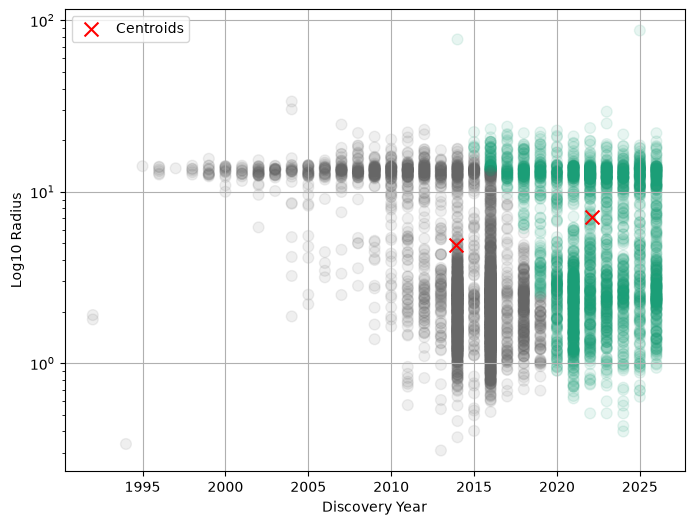

Silhouette Score: 0.3808401399109702
Davies-Bouldin Score: 1.270327456011274
Calinski-Harabasz Score: 2951.027005982216


In [27]:
def radius_over_year_kmeans(k):
    centroids, clusters = kmeans2(data, k, minit='++')

    plt.figure(figsize=(8, 6))

    plt.scatter(
        data[:, 0],
        data[:, 1],
        c=clusters,
        cmap='Dark2',
        s=60,
        alpha=0.1
    )

    plt.scatter(
        centroids[:, 0],
        centroids[:, 1],
        c='red',
        marker='x',
        s=100,
        label='Centroids'
    )

    plt.xlabel("Discovery Year")
    plt.ylabel("Log10 Radius")
    plt.yscale("log")
    plt.grid(True)
    plt.legend()
    plt.show()

    print("Silhouette Score:", silhouette_score(data, clusters))
    print("Davies-Bouldin Score:", davies_bouldin_score(data, clusters))
    print("Calinski-Harabasz Score:", calinski_harabasz_score(data, clusters))

radius_over_year_kmeans(2)

# Results
- The silhouette score came in at 0.53. The score ranges from -1 to 1, and
values above 0.5 are usually read as reasonable cluster structure. For our graph the score means most planets sit closer to their own clusters than to any other. There is some overlap between the clusters.
- The Davies-Bouldin index was 0.93. Lower is better, and better scores communicate that the clusters are well-separated and tightly packed.
- The Calinski-Harabasz index was 5255.3. This index measures how similar an object is to its own clusters

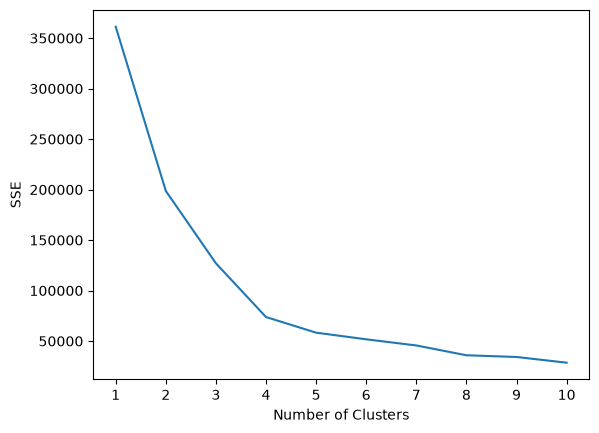

In [28]:
# https://www.statology.org/elbow-method-in-python/
from sklearn.cluster import KMeans

kmeans_kwargs = {
"init": "random",
"n_init": 10,
"random_state": 1,
}

#create list to hold SSE values for each k
sse = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, **kmeans_kwargs)
    kmeans.fit(d)
    sse.append(kmeans.inertia_)

#visualize results
plt.plot(range(1, 11), sse)
plt.xticks(range(1, 11))
plt.xlabel("Number of Clusters")
plt.ylabel("SSE")
plt.show()

## 4 Clusters

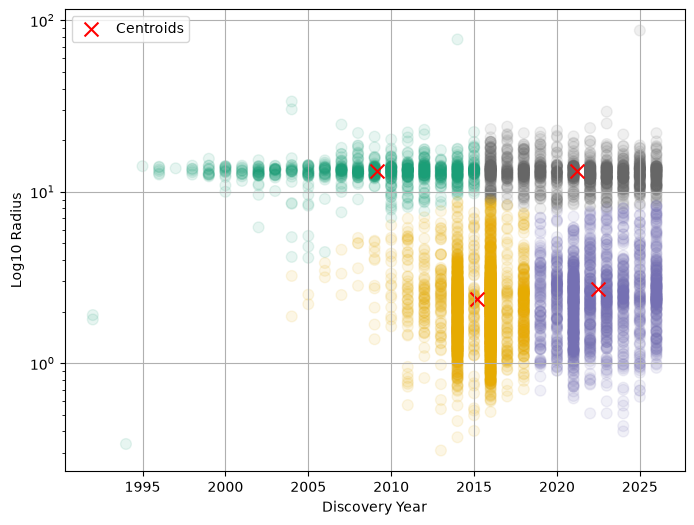

Silhouette Score: 0.5699156033444562
Davies-Bouldin Score: 0.607748859580126
Calinski-Harabasz Score: 8328.190357344143


In [29]:
radius_over_year_kmeans(4)

## Results and Conclusion

idk man

The clustering model provides a much clearer view of the situation. By graphing the log of the planets' radius over their discovery years, we 